In [ ]:
#!pip install nltk seaborn

In [1]:
import numpy as np
import pandas as pd

import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt
import seaborn as sns
import contractions
#import sys  
#!{sys.executable} -m pip install contractions
#import contractions

In [ ]:
#!pip install contractions==0.0.18

In [2]:
%matplotlib inline

plt.rcParams['figure.figsize'] = [14,7]
plt.rcParams['figure.dpi'] = 70

In [3]:
df = pd.read_csv('the-office_lines.csv')
df.head()

,Unnamed: 0,Character,Line,Season,Episode_Number
0,0,Michael,All right Jim. Your quarterlies look very goo...,1,1
1,1,Jim,"Oh, I told you. I couldn’t close it. So…",1,1
2,2,Michael,So you’ve come to the master for guidance? Is...,1,1
3,3,Jim,"Actually, you called me in here, but yeah.",1,1
4,4,Michael,"All right. Well, let me show you how it’s don...",1,1


In [4]:
df['Character'].nunique()

780

In [5]:
df['Character'].unique()

array(['Michael', 'Jim', 'Pam', 'Dwight', 'Jan', 'Michel', 'Todd Packer',
       'Phyllis', 'Stanley', 'Oscar', 'Angela', 'Kevin', 'Ryan', 'Man',
       'Roy', 'Documentary Crew Member', 'Mr. Brown', 'Toby', 'Kelly',
       'Meredith', 'Travel Agent', 'Man On Phone', 'Everybody', 'Lonny',
       'Darryl', 'Teammates', 'Michael And Dwight', 'Warehouse Worker',
       'Madge', 'Worker', 'Packer', 'Katy', 'Guy At Bar', 'Pam And Jim',
       'Employee', 'Chili’S Employee', 'Waitress', 'Manager',
       'Kevin’S Computer', 'Warehouse Guy', 'Warehouse Guys', 'Video',
       'Man In Video', 'Actor', 'Redheaded Actress', 'Mr. O’Malley',
       'Albiny', 'Pam’S Mom', 'Carol', 'Bill', 'Everyone', 'Crowd',
       'Song', 'Dwight And Michael', 'Sherri', 'Creed', 'Devon',
       'Children', 'Kid', 'Vance Refrigeration Worker #1',
       'Vance Refrigeration Worker #2', 'Hank The Security Guard', 'Ira',
       'Ryan’S Voicemail', 'Master', 'Alyssa', 'Christian', 'Hostess',
       'Michael And Christ

In [6]:
df['Count'] = df.groupby('Line')['Line'].transform('count')
df.sort_values(by='Count', ascending=False, inplace = True)
df.head()

,Unnamed: 0,Character,Line,Season,Episode_Number,Count
25781,27135,Dwight,Yeah.,5,12,254
25549,26892,David,Yeah.,5,11,254
16904,17935,Michael,Yeah.,4,1,254
11109,11810,Ryan,Yeah.,3,6,254
23698,24971,Michael,Yeah.,5,5,254


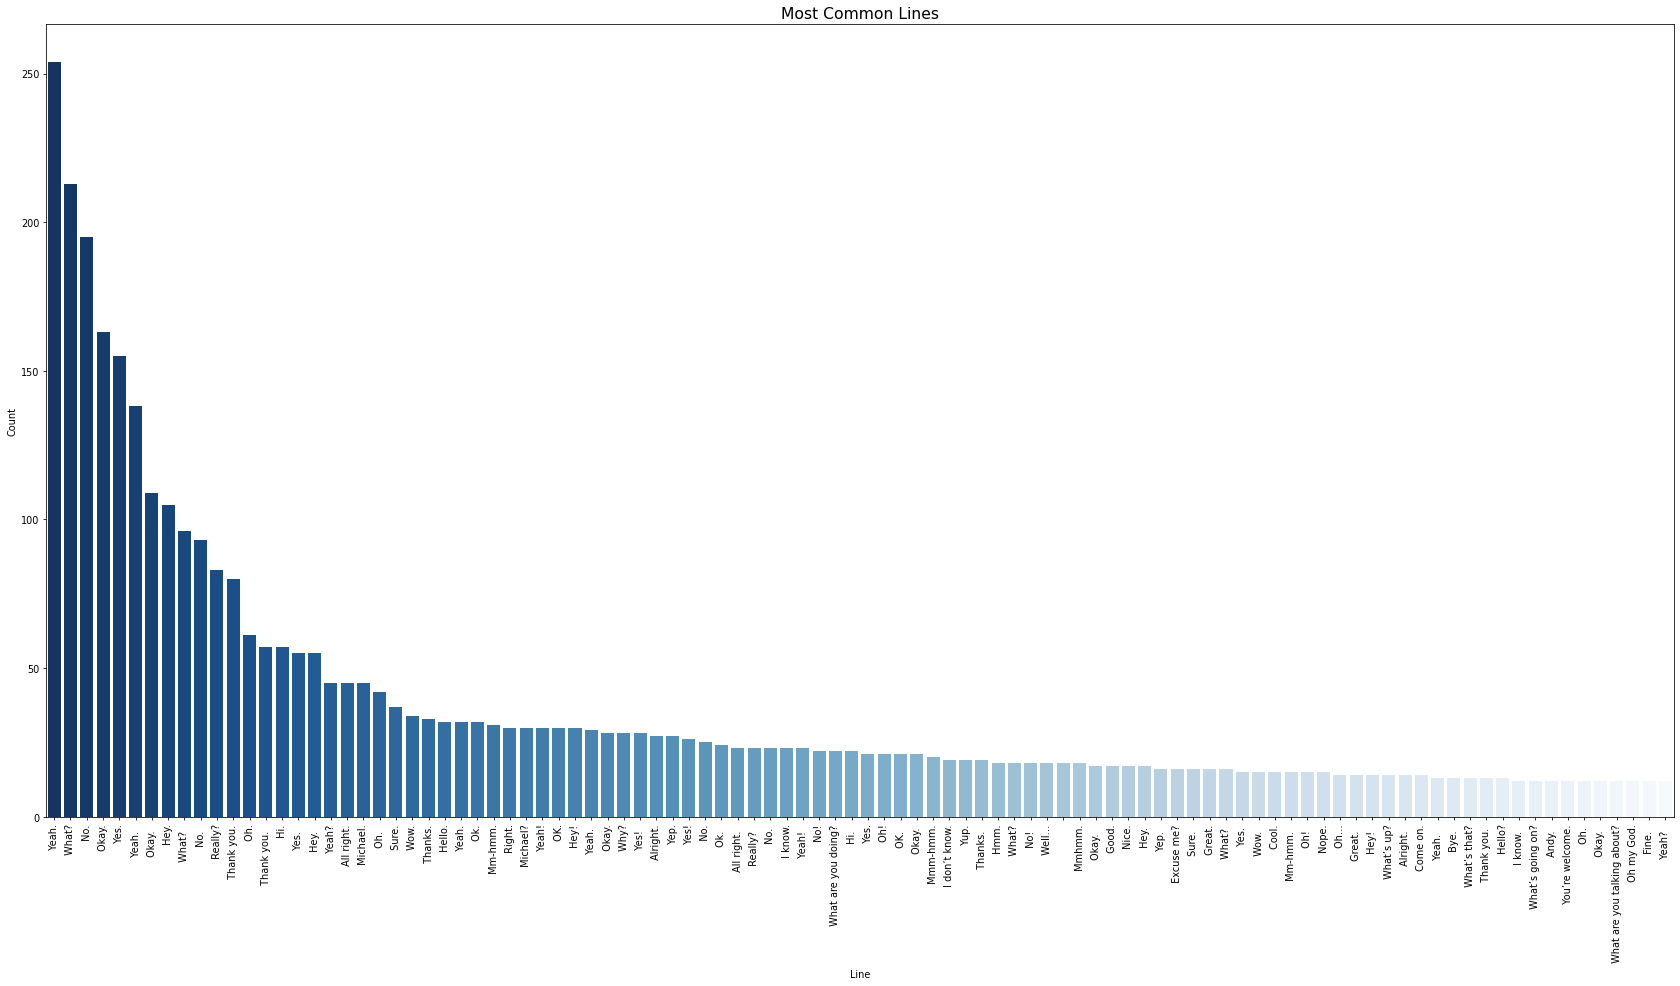

In [7]:
Line = df.drop_duplicates(subset=['Line'])
Line100 = Line.head(100)
plt.figure(figsize=(30,15))
Lines = sns.barplot(data=Line100, x = 'Line', y = 'Count', palette = 'Blues_r')
Lines.set_xticklabels(Lines.get_xticklabels(), rotation=90)
Lines.set_title('Most Common Lines',fontsize=16);

In [ ]:
#df.groupby('Character')['Line'].count().sort_values(ascending=False).head(20)

In [8]:
df.loc[:, ['Character', 'Line']].groupby(['Character']).count().sort_values(by='Line',ascending=False).head(20)

,Line
Character,
Michael,11806
Dwight,7393
Jim,6666
Pam,5264
Andy,3933
Kevin,1678
Angela,1677
Oscar,1464
Erin,1452


In [9]:
michael = df[df.Character=='Michael']
dwight = df[df.Character=='Dwight']
jim = df[df.Character=='Jim']
pam = df[df.Character=='Pam']
andy = df[df.Character=='Andy']
kevin = df[df.Character=='Kevin']
angela = df[df.Character=='Angela']
oscar = df[df.Character=='Oscar']
erin = df[df.Character=='Erin']
ryan = df[df.Character=='Ryan']
darryl = df[df.Character=='Darryl']
phyllis = df[df.Character=='Phyllis']
toby = df[df.Character=='Toby']
jan = df[df.Character=='Jan']
kelly = df[df.Character=='Kelly']
stanley = df[df.Character=='Stanley']
meredith = df[df.Character=='Meredith']
holly = df[df.Character=='Holly']
nellie = df[df.Character=='Nellie']
creed = df[df.Character=='Creed']

In [10]:
michael.head()

,Unnamed: 0,Character,Line,Season,Episode_Number,Count
16904,17935,Michael,Yeah.,4,1,254
23698,24971,Michael,Yeah.,5,5,254
11083,11782,Michael,Yeah.,3,6,254
27727,29159,Michael,Yeah.,5,20,254
24873,26194,Michael,Yeah.,5,9,254


In [11]:
text = creed['Line']
text = text.to_string()
text = contractions.fix(text)
tokens = [t for t in text.split()]
print(tokens)

['25564', 'Yeah.', '6773', 'What?', '3809', 'No.', '39471', 'No.', '5559', 'Okay.', '14013', 'Okay.', '52727', 'What?', '5923', 'All', 'right.', '14011', 'Sure.', '17279', 'Thanks.', '15524', 'Hey!', '15036', 'Hey!', '48462', 'All', 'right.', '30488', 'Yep.', '30456', 'Yes.', '21577', 'Mm-hmm.', '38513', 'you', 'are', 'welcome.', '5919', 'I…', '22889', 'Ugh.', '18676', 'Exactly.', '10282', 'About', 'what?', '17646', 'Yes,', 'sir.', '41038', 'Yes,', 'sir.', '15278', 'Here.', '40628', 'Thank', 'you', 'very', 'much.', '10284', 'Ed', 'was', 'decapitated.', '3691', 'Huh?', '3702', 'Can', 'I', 'go?', '9537', ':', '54947', 'Night', '46035', 'Oh', 'my', 'goodness.', '39764', 'we', 'are', 'working.', '[Jim', 'still', 'holding', 'his', 'breath]', '39762', 'How', 'far', 'can', 'you', 'reach', 'those', 'Lovely', 'long', 'arms', '...', '39760', 'Hey,', 'kid–hear', 'you', 'are', 'looking', 'for', 'work.', '38961', 'Best', 'Edward', 'James', 'Olmos', 'costume', 'I', 'have', 'ever', 'see...', '43267',

In [12]:
nltk.download('stopwords')
#nltk.download()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Jennifer\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [13]:
sw= stopwords.words('english')
clean_tokens = tokens[:]
for token in tokens:
    if token in sw:        
        clean_tokens.remove(token)
print(clean_tokens)

['25564', 'Yeah.', '6773', 'What?', '3809', 'No.', '39471', 'No.', '5559', 'Okay.', '14013', 'Okay.', '52727', 'What?', '5923', 'All', 'right.', '14011', 'Sure.', '17279', 'Thanks.', '15524', 'Hey!', '15036', 'Hey!', '48462', 'All', 'right.', '30488', 'Yep.', '30456', 'Yes.', '21577', 'Mm-hmm.', '38513', 'welcome.', '5919', 'I…', '22889', 'Ugh.', '18676', 'Exactly.', '10282', 'About', 'what?', '17646', 'Yes,', 'sir.', '41038', 'Yes,', 'sir.', '15278', 'Here.', '40628', 'Thank', 'much.', '10284', 'Ed', 'decapitated.', '3691', 'Huh?', '3702', 'Can', 'I', 'go?', '9537', ':', '54947', 'Night', '46035', 'Oh', 'goodness.', '39764', 'working.', '[Jim', 'still', 'holding', 'breath]', '39762', 'How', 'far', 'reach', 'Lovely', 'long', 'arms', '...', '39760', 'Hey,', 'kid–hear', 'looking', 'work.', '38961', 'Best', 'Edward', 'James', 'Olmos', 'costume', 'I', 'ever', 'see...', '43267', 'I', 'watch', 'sleep.', '39424', 'HI', 'mahhhh.', 'Boo', 'yowww.', 'Gunjo!', 'Ooh', 'uncow!', '39422', 'Beleniege

In [16]:
print(len(tokens), len(clean_tokens))

3430 2459


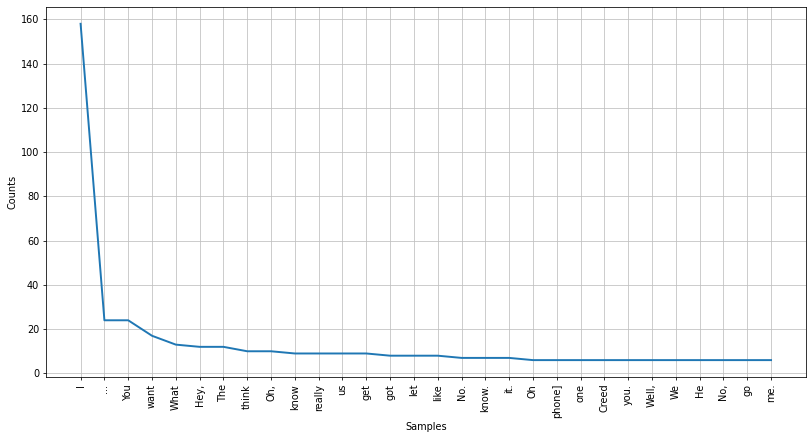

<AxesSubplot:xlabel='Samples', ylabel='Counts'>

In [14]:
freq = nltk.FreqDist(clean_tokens)
freq.plot(30, cumulative=False)